<a href="https://colab.research.google.com/github/pendulumswings/pendulumswings.github.io/blob/main/scripts/chapter4/pinn_2_hidden_layer_jax.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

2 Hidden Layer PINN to solve the pendulum equation for the first $25$ secs using JAX. Drop angle is $\pi/4=45^{\circ}$ from rest

Starting training with JAX + SciPy L-BFGS-B (1153 parameters)...
Compiling JAX graph on the first step, then training will fly...


/tmp/ipykernel_869/974433775.py:142: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  res = minimize(


JAX 2-Layer | Iteration  100 | Loss: 0.008236
JAX 2-Layer | Iteration  200 | Loss: 0.006240
JAX 2-Layer | Iteration  300 | Loss: 0.005750
JAX 2-Layer | Iteration  400 | Loss: 0.005341
JAX 2-Layer | Iteration  500 | Loss: 0.004880
JAX 2-Layer | Iteration  600 | Loss: 0.004339
JAX 2-Layer | Iteration  700 | Loss: 0.004224
JAX 2-Layer | Iteration  800 | Loss: 0.003884
JAX 2-Layer | Iteration  900 | Loss: 0.003641
JAX 2-Layer | Iteration 1000 | Loss: 0.003355
JAX 2-Layer | Iteration 1100 | Loss: 0.003232
JAX 2-Layer | Iteration 1200 | Loss: 0.003006
JAX 2-Layer | Iteration 1300 | Loss: 0.002909
JAX 2-Layer | Iteration 1400 | Loss: 0.002800
JAX 2-Layer | Iteration 1500 | Loss: 0.002747
JAX 2-Layer | Iteration 1600 | Loss: 0.002681
JAX 2-Layer | Iteration 1700 | Loss: 0.002661
JAX 2-Layer | Iteration 1800 | Loss: 0.002653

Training Complete! Final Loss: 0.002651


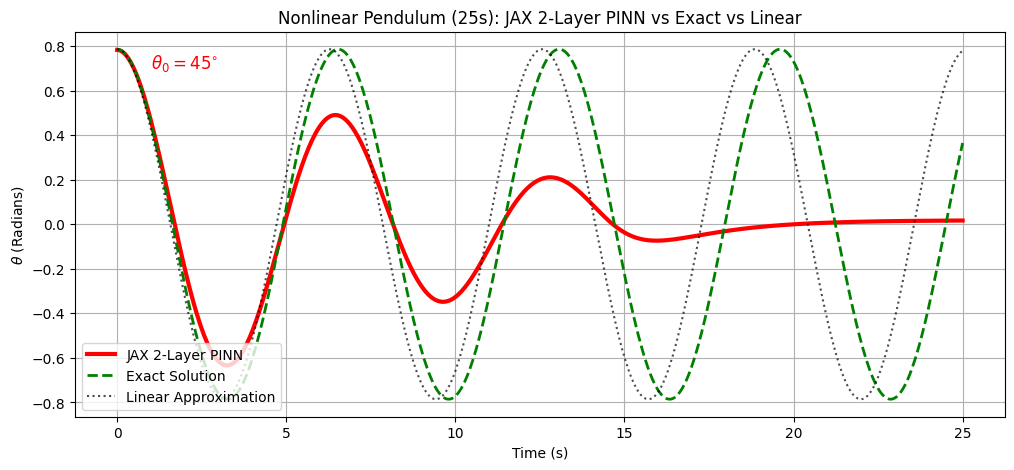

In [1]:
import jax
import jax.numpy as jnp
from jax import jit, value_and_grad

# CRITICAL: SciPy's optimizer uses 64-bit precision floats.
# JAX defaults to 32-bit. We must force JAX to use 64-bit to prevent crashes!
jax.config.update("jax_enable_x64", True)

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
import scipy.special as sp

def unpack_weights(params, H):
    """Reconstructs the weight matrices from the flat 1D array for 2 hidden layers."""
    idx = 0

    # Layer 1
    W1 = params[idx : idx+H].reshape(1, H); idx += H
    b1 = params[idx : idx+H].reshape(1, H); idx += H

    # Layer 2 (H inputs to H outputs)
    W2 = params[idx : idx+H*H].reshape(H, H); idx += H*H
    b2 = params[idx : idx+H].reshape(1, H); idx += H

    # Output Layer
    W3 = params[idx : idx+H].reshape(H, 1); idx += H
    b3 = params[idx : idx+1].reshape(1, 1)

    return W1, b1, W2, b2, W3, b3

def pack_weights(W1, b1, W2, b2, W3, b3):
    """Flattens weights into a 1D array for SciPy."""
    return np.concatenate([
        W1.flatten(), b1.flatten(),
        W2.flatten(), b2.flatten(),
        W3.flatten(), b3.flatten()
    ])

def forward_with_physics(params, t, H):
    """
    Calculates position, velocity, and acceleration analytically for a 2-layer network.
    We use jnp (JAX NumPy) so the AutoDiff engine can map these operations.
    """
    W1, b1, W2, b2, W3, b3 = unpack_weights(params, H)

    # --- TIME SCALING ---
    t_max = 25.0
    tau = t / t_max
    dtau_dt = 1.0 / t_max

    # 1. Feed-Forward
    z1 = jnp.dot(tau, W1) + b1
    a1 = jnp.tanh(z1)

    z2 = jnp.dot(a1, W2) + b2
    a2 = jnp.tanh(z2)

    theta = jnp.dot(a2, W3) + b3

    # 2. First Derivative (Velocity) - Chain Rule
    da1_dtau = (1 - a1**2) * W1
    dz2_dtau = jnp.dot(da1_dtau, W2)
    da2_dtau = (1 - a2**2) * dz2_dtau
    velocity = jnp.dot(da2_dtau, W3) * dtau_dt

    # 3. Second Derivative (Acceleration) - Product Rule & Chain Rule
    d2a1_dtau2 = -2 * a1 * (1 - a1**2) * (W1**2)
    d2z2_dtau2 = jnp.dot(d2a1_dtau2, W2)

    # Product rule applied here: d(u*v) = u'*v + u*v'
    d2a2_dtau2 = -2 * a2 * da2_dtau * dz2_dtau + (1 - a2**2) * d2z2_dtau2
    acceleration = jnp.dot(d2a2_dtau2, W3) * (dtau_dt**2)

    return theta, velocity, acceleration

# Define the function normally first
def compute_loss(params, t_domain, t_ic, theta_0, omega_0, H):
    """Calculates the total error across the domain and initial conditions."""
    # Physics Loss
    theta, _, acceleration = forward_with_physics(params, t_domain, H)
    residual = acceleration + jnp.sin(theta)
    loss_ode = jnp.mean(residual**2)

    # Initial Condition Loss
    theta_pred_ic, velocity_pred_ic, _ = forward_with_physics(params, t_ic, H)
    loss_ic_position = jnp.mean((theta_pred_ic - theta_0)**2)
    loss_ic_velocity = jnp.mean((velocity_pred_ic - omega_0)**2)

    # FIX: Remove the 100.0 penalty! We must let the ODE and IC gradients balance naturally.
    return loss_ode + loss_ic_position + loss_ic_velocity

# Explicitly wrap the function in JIT, telling it H is a static integer
compute_loss = jit(compute_loss, static_argnums=(5,))

# JAX automatic backpropagation magic: exact gradients instantly.
loss_and_grad = jit(value_and_grad(compute_loss), static_argnums=(5,))

def scipy_objective(params, t_domain, t_ic, theta_0, omega_0, H):
    """Wrapper to feed JAX results back into SciPy's format."""
    loss, grads = loss_and_grad(params, t_domain, t_ic, theta_0, omega_0, H)
    return float(loss), np.array(grads)

# ==========================================
# Training Setup (25 Seconds)
# ==========================================

H = 32  # Number of hidden neurons per layer
t_domain = jnp.linspace(0, 25, 500).reshape(-1, 1)
t_ic = jnp.array([[0.0]])
theta_0 = jnp.pi / 4
omega_0 = 0.0

# Initialize Random Weights (Glorot style initialization)
np.random.seed(42)

# CRITICAL FIX: Multiply W1 by 10.0 to overcome Spectral Bias!
# By making the input weights much larger, we force the network to start
# with high-frequency "wiggles" rather than a flat line, breaking its laziness!
W1 = np.random.randn(1, H) * 10.0
b1 = np.zeros((1, H))

W2 = np.random.randn(H, H) * np.sqrt(2.0 / (H + H))
b2 = np.zeros((1, H))
W3 = np.random.randn(H, 1) * np.sqrt(2.0 / (H + 1))
b3 = np.zeros((1, 1))

initial_weights = pack_weights(W1, b1, W2, b2, W3, b3)

# --- Callback for Progress Tracking ---
progress = {'iterations': 0}

def monitor_progress(xk):
    progress['iterations'] += 1
    if progress['iterations'] % 100 == 0:
        current_loss = compute_loss(xk, t_domain, t_ic, theta_0, omega_0, H)
        print(f"JAX 2-Layer | Iteration {progress['iterations']:4d} | Loss: {float(current_loss):.6f}")

print(f"Starting training with JAX + SciPy L-BFGS-B ({len(initial_weights)} parameters)...")
print("Compiling JAX graph on the first step, then training will fly...")

res = minimize(
    fun=scipy_objective,
    x0=initial_weights,
    args=(t_domain, t_ic, theta_0, omega_0, H),
    method='L-BFGS-B',
    jac=True, # CRITICAL: We provide the exact gradients from JAX!
    callback=monitor_progress,
    options={'maxiter': 10000, 'maxfun': 500000, 'disp': False}
)

final_weights = res.x
print(f"\nTraining Complete! Final Loss: {res.fun:.6f}")

# ==========================================
# Evaluation and Plotting
# ==========================================

theta_predicted, _, _ = forward_with_physics(final_weights, t_domain, H)

# Convert JAX arrays back to NumPy for Matplotlib
t_plot = np.array(t_domain).flatten()
theta_plot = np.array(theta_predicted).flatten()

# Exact Solution (Jacobi Elliptic)
k = np.sin(theta_0 / 2)
m = k**2
sn, cn, dn, ph = sp.ellipj(t_plot, m)
exact_solution = 2 * np.arcsin(k * (cn / dn))

# Linear Solution (Small Angle Approximation)
linear_solution = theta_0 * np.cos(t_plot)

plt.figure(figsize=(12, 5))
plt.plot(t_plot, theta_plot, 'r-', linewidth=3, label='JAX 2-Layer PINN')
plt.plot(t_plot, exact_solution, 'g--', linewidth=2, label='Exact Solution')
plt.plot(t_plot, linear_solution, 'k:', alpha=0.7, label='Linear Approximation')

plt.title("Nonlinear Pendulum (25s): JAX 2-Layer PINN vs Exact vs Linear")
plt.text(1, 0.7, "$\\theta_{0}=45^{\\circ}$", fontsize=12, color='red',
         bbox=dict(facecolor='white', alpha=0.8, edgecolor='none'))
plt.xlabel("Time (s)")
plt.ylabel("$\\theta$ (Radians)")
plt.legend(loc='lower left')
plt.grid(True)
plt.show()